# Week 10 · Session 2 · Part B — Is something changing?
## From anomalies to trends: Mann–Kendall, Sen's slope and maps of trends

**Geoprocesamiento · Maestría en Geomática · Universidad Nacional de Colombia**

Part A did **step 1**: it removed the seasonal cycle $S$ and looked at the anomaly. Part B does the other two steps:

| Step | Remove | What is left | Question |
|---|---|---|---|
| 2 | the noise $\varepsilon$ (average each year) | $I + T$ | **Is it changing?** → the slope of a line ($T$) |
| 3 | the trend $T$ (subtract the line) | $I$ | **Which years were different?** |

A trend has two questions, and each has its tool:

| Question | Tool | Answer |
|---|---|---|
| Is there a monotonic change, or could it be chance? | **Mann–Kendall test** | S, Kendall's τ and a p-value |
| How much does it change per year? | **Theil–Sen slope** | NDVI per year |

**Significant does not mean large, and large does not mean significant.** Always report both.

## 0 · Setup
**0.1 · The working folder** (the same check as Part A: Jupyter Lab must be opened from the course folder).

In [1]:
# ---- Check the working folder (Jupyter Lab, Anaconda) ----
# Open Jupyter Lab FROM the course folder, the one that contains "src/ts_tools.py" and the .h5 files.
import os
print("Working folder:", os.getcwd())
print("Is the toolbox here?", os.path.exists("src/ts_tools.py"))

# If a library is missing, remove the "#" of ONE of these lines, run it once, then restart the kernel:
# %conda install -y -c conda-forge h5py scipy statsmodels folium pystac-client planetary-computer odc-stac
# %pip install h5py scipy statsmodels folium pystac-client planetary-computer odc-stac pymannkendall

# Autoreload: if you edit src/ts_tools.py, the notebook uses the new version without restarting the kernel.
%load_ext autoreload
%autoreload 2

Working folder: C:\Users\FCA-UN-2240386\OneDrive - Universidad Nacional de Colombia\1_Periodos_Asignaturas\Cursos_2026_2\Geoprocesamiento\notebooks_borrador\Anomalies
Is the toolbox here? True


In [7]:
import numpy as np                  # arrays and maths
import pandas as pd                 # tables and dates
import matplotlib.pyplot as plt     # figures
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)      # "mean of empty slice" with missing data: expected
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from src import ts_tools as tt      # our toolbox (src/ts_tools.py)

MODIS_FILE = "saldana_modis_ndvi_2001_2015_terra_aqua.h5"     # the same file as Part A (use the same name you used there)
TREND_FILE = "saldana_modis_trends_2001_2015.h5"              # the result we save at the end
P = 46                                                        # composites per year
REF_YEARS = (2001, 2015)

cube = tt.load_cube_hdf5(MODIS_FILE)     # read the cube saved in Part A
ndvi = cube["ndvi"]                      # NDVI values: (time, rows, columns); NaN = no reliable value
dates = pd.DatetimeIndex(cube["time"])   # the date of each layer
print("Shape (time, rows, columns):", ndvi.shape)

Shape (time, rows, columns): (690, 80, 81)


In [4]:
# The same three pixels as Part A, and their tables (years x composites) of OBSERVED values.
# In Part B we never test values that were filled: a filled value is "normal" by construction.
# The pixels you chose in Part A (A1) were saved in my_pixels.json
import os, json
if os.path.exists("my_pixels.json"):                 # the file written in section A1 of Part A
    with open("my_pixels.json") as f:                # "with" opens the file and closes it at the end
        saved = json.load(f)                         # a dictionary: name -> [row, col]
    PIXELS = {}
    for name in saved:
        PIXELS[name] = tuple(saved[name])            # back to (row, col)
    print("Pixels chosen in Part A:", PIXELS)
else:
    # without the file we fall back to automatic pixels: they may NOT match the classes (see Part A, A1)
    auto = tt.example_pixels(ndvi)
    PIXELS = {"seasonal crop": auto["seasonal crop"], "stable vegetation": auto["stable vegetation"],
              "river sandbar": auto["intermediate"]}
    print("my_pixels.json not found (run section A1 of Part A first): using automatic pixels", PIXELS)
COLOURS = {"seasonal crop": "#2B580C", "stable vegetation": "#7B4F9E", "river sandbar": "#D9732B"}

# For each pixel, its observed series as a table: one row per year, one column per composite (1...46)
TABLES = {}
for name in PIXELS:
    row, col = PIXELS[name]
    TABLES[name] = tt.year_period_table(ndvi[:, row, col], dates)
    print(f"{name:18s}: table of {TABLES[name].shape[0]} years x {TABLES[name].shape[1]} composites")

Pixels chosen in Part A: {'seasonal crop': (45, 33), 'stable vegetation': (33, 38), 'river sandbar': (31, 23)}
seasonal crop     : table of 15 years x 46 composites
stable vegetation : table of 15 years x 46 composites
river sandbar     : table of 15 years x 46 composites


# Part B · Is something changing?

### B1 · From the anomaly to the trend, step by step
We follow one pixel through the three steps, so that every later method has a clear place:

* **Step 1 (Part A): remove S.** anomaly = observed − climatology. Left: $I + T + \varepsilon$.
* **Step 2: remove ε.** The mean anomaly of each year: the noise goes up and down and largely cancels. Left: $I + T$, one value per year. A line through those values (Sen's slope, B3) is **T**.
* **Step 3: remove T.** Each yearly value minus the line. Left: **I**, how far each year was from its trend.

In [10]:
name = "seasonal crop"                                    # try also "stable vegetation" or "river sandbar"
table = TABLES[name]                                      # observed values: years x composites

# Step 1 - remove S: subtract the climatology (Part A)
clim = tt.climatology(table, ref_years=REF_YEARS)
anomaly_table = tt.anomalies(table, clim)                 # absolute anomaly a, years x composites
print("Step 1 - anomaly of the first 5 composites of 2001:", anomaly_table.loc[2001].values[:5].round(3))

Step 1 - anomaly of the first 5 composites of 2001: [nan nan nan nan nan]


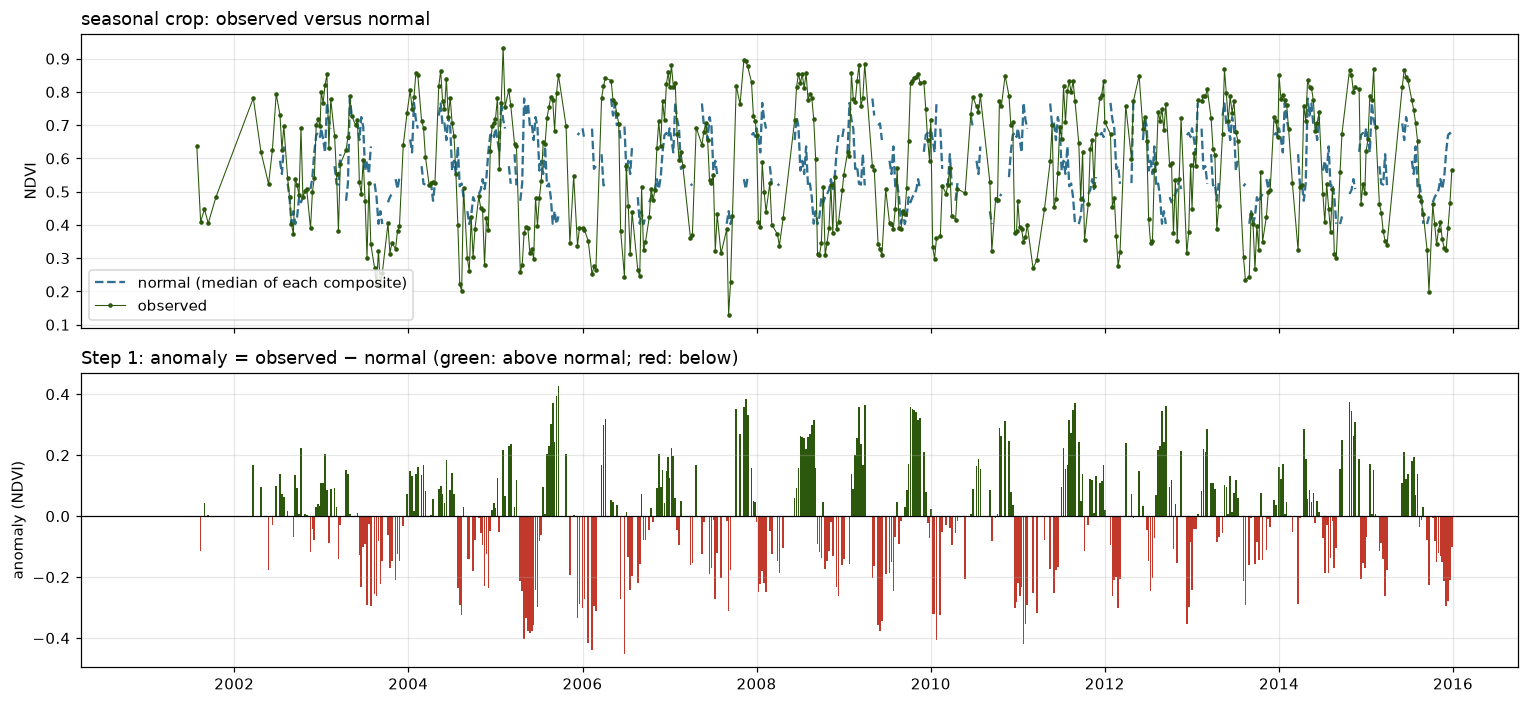

In [19]:
# ---------------------------------------------------------------------------
# Visualising Step 1: the observed series, the normal series and their difference
# ---------------------------------------------------------------------------
# Step 1 subtracted the climatology (the "typical year") from every value.
# Seen as a table it is hard to read, so here we put everything back in time
# order and draw it as a time series: what happened, what usually happens at
# that time of year, and the gap between the two (the anomaly).

# table_to_series undoes year_period_table: it reads the table row by row
# (2001 composite 1, 2001 composite 2, ..., 2015 composite 46) and returns a
# numpy array in time order. Being numpy arrays, they have no ".values".
obs_s = tt.table_to_series(table)              # the observed NDVI (NaN where there was no data)

# "table * 0" gives a table of the same shape filled with zeros (NaN stays NaN);
# adding clim["centre"] fills each column with the median of its composite.
# The result is the typical year repeated in every year, aligned with the data.
normal = table * 0 + clim["centre"]
norm_s = tt.table_to_series(normal)            # the normal value for each date

anom_s = tt.table_to_series(anomaly_table)     # the anomaly: observed minus normal
d = dates[:len(obs_s)]                         # one date per value, in the same order

# Two panels, one above the other, sharing the same time axis
fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)

# --- Top panel: observed versus normal ---
# The observed line is drawn only where there is data: otherwise the NaN
# would break it into many short pieces. ok is True for every value with data.
ok = ~np.isnan(obs_s)
axes[0].plot(d, norm_s, "--", color="#2F6F8F", lw=1.5,
             label="normal (median of each composite)")
axes[0].plot(d[ok], obs_s[ok], "o-", ms=2, lw=0.7, color="#2B580C",
             label="observed")
axes[0].set_ylabel("NDVI")
axes[0].legend(loc="lower left")
axes[0].set_title(f"{name}: observed versus normal", loc="left")

# --- Bottom panel: the anomaly, i.e. the vertical gap between the two lines above ---
# tt.bars draws green bars above zero (above normal) and red bars below zero.
tt.bars(axes[1], d, anom_s, width=7)           # width in days: one composite is 8 days
axes[1].axhline(0, color="k", lw=0.8)          # the zero line: "exactly normal"
axes[1].set_ylabel("anomaly (NDVI)")
axes[1].set_title("Step 1: anomaly = observed − normal (green: above normal; red: below)",
                  loc="left")

plt.tight_layout()                             # adjust the margins so that titles and labels do not overlap
plt.show()

In [16]:
# Step 2 - remove the noise: the mean of each ROW of the anomaly table (one value per year).
# min_share=0.6: a year needs at least 60 % of its 46 composites with data, otherwise it is left out (NaN)
yearly = tt.annual_aggregate(anomaly_table, how="mean", min_share=0.6)
print("Step 2 - mean anomaly of each year (I + T):")
print(yearly.round(3).to_string())

Step 2 - mean anomaly of each year (I + T):
year
2001      NaN
2002      NaN
2003   -0.061
2004   -0.006
2005   -0.020
2006   -0.055
2007    0.021
2008   -0.019
2009    0.044
2010   -0.020
2011   -0.005
2012   -0.016
2013   -0.000
2014    0.037
2015   -0.040


Years with a yearly mean: [2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015]
Years left out (fewer than 60 % of composites with data): [2001, 2002]


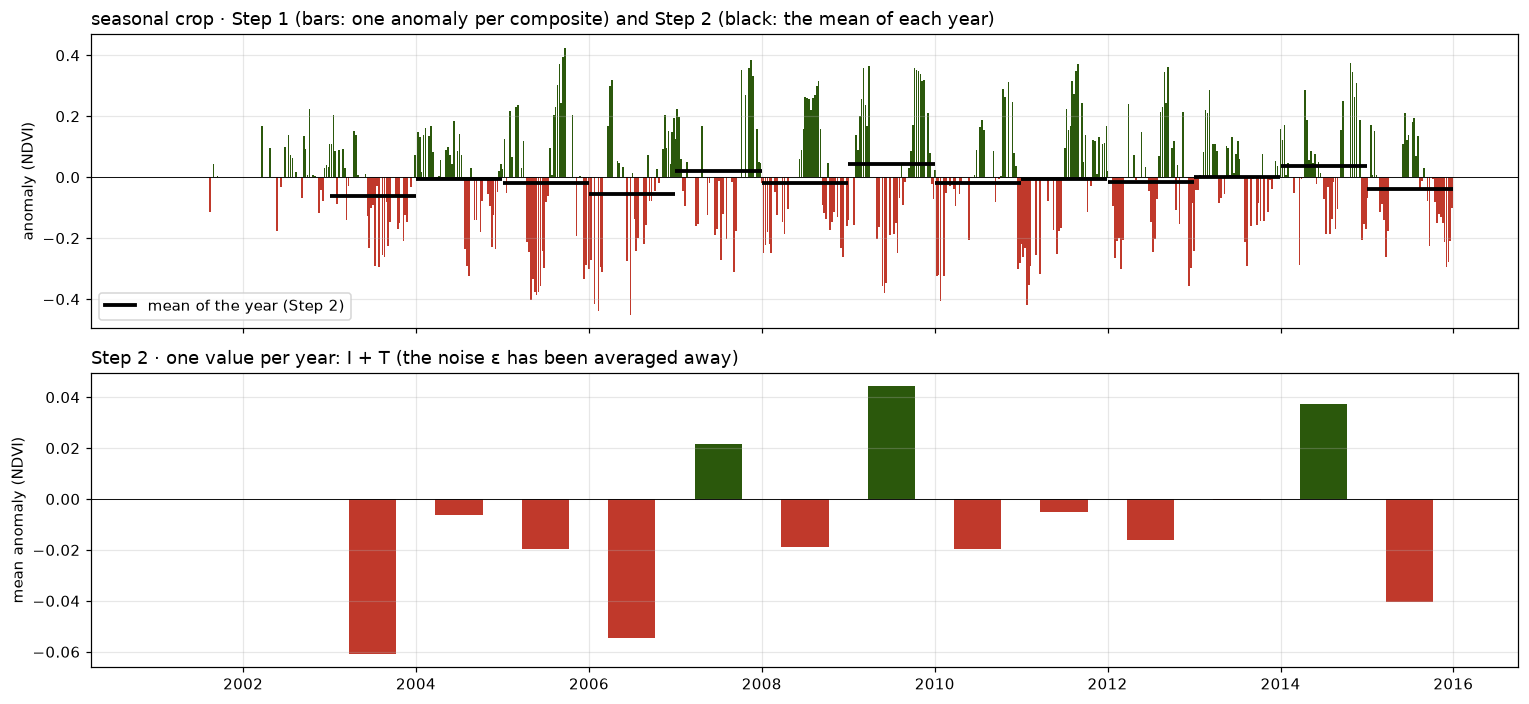

In [18]:
# ---------------------------------------------------------------------------
# Visualising Step 2: from many anomalies per year to ONE value per year
# ---------------------------------------------------------------------------
# Step 1 left one anomaly per composite (46 per year): I + T + ε.
# Step 2 averages each year, so the fast ups and downs (the noise ε) cancel out
# and only the level of each year is left: I + T.
# This figure shows both at once, so you can see what the averaging removes.

# The anomalies back in time order: table_to_series reads the table row by row
# (2001 composite 1, 2001 composite 2, ..., 2015 composite 46).
# It returns a numpy array, so there is no ".values" to add.
anom_s = tt.table_to_series(anomaly_table)
d = dates[:len(anom_s)]                       # one date per value, in the same order

# The yearly means as dates, so they can share the same time axis as the anomalies.
# We place each year's value in the middle of that year (1 July).
year_mid = pd.to_datetime([f"{y}-07-01" for y in yearly.index])

# Years that were left out by min_share (too few composites with data) are NaN.
kept = ~np.isnan(yearly.values)               # True for the years that have a mean
print("Years with a yearly mean:", list(yearly.index[kept]))
print("Years left out (fewer than 60 % of composites with data):", list(yearly.index[~kept]))

fig, axes = plt.subplots(2, 1, figsize=(14, 6.5), sharex=True)

# --- Top panel: the composite anomalies (Step 1) with the yearly means on top ---
tt.bars(axes[0], d, anom_s, width=7)          # green above normal, red below
for y, m in zip(yearly.index[kept], yearly.values[kept]):
    # a horizontal black segment across the whole year at the height of its mean:
    # it is the "summary" of all the bars underneath it
    axes[0].hlines(m, pd.Timestamp(f"{y}-01-01"), pd.Timestamp(f"{y}-12-31"),
                   colors="k", lw=2.5)
axes[0].plot([], [], "k", lw=2.5, label="mean of the year (Step 2)")   # an empty line, only for the legend
axes[0].legend(loc="lower left")
axes[0].set_ylabel("anomaly (NDVI)")
axes[0].set_title(f"{name} · Step 1 (bars: one anomaly per composite) and Step 2 (black: the mean of each year)",
                  loc="left")

# --- Bottom panel: only the yearly means, i.e. what Step 2 keeps ---
tt.bars(axes[1], year_mid[kept], yearly.values[kept], width=200)   # width in days: a wide bar per year
axes[1].set_ylabel("mean anomaly (NDVI)")
axes[1].set_title("Step 2 · one value per year: I + T (the noise ε has been averaged away)", loc="left")

plt.tight_layout(); plt.show()

#### Step 2 (continued) and Step 3 · The trend line, and what is left when we remove it

After Step 2 we have **one value per year**: the mean anomaly of that year, which still contains two things, $I + T$ (the year-to-year variation and the trend). The next cell separates them in two moves.

**1 · Draw the trend line through the yearly values (this is $T$).**
We fit a straight line through the yearly means with **Sen's slope** (worked out by hand in B3). Instead of least squares, Sen's method takes the slope between **every pair of years** and keeps the **median** of all those slopes, so one extreme year (El Niño 2010, for example) cannot tilt the line. The line is

$$ T(\text{year}) = \text{intercept} + \text{slope} \times \text{year} $$

and the cell reports the slope in two units:

* **NDVI per year**: how much the level changes from one year to the next;
* **NDVI per decade** (the same number × 10): easier to read, because changes in NDVI are small.

 The slope says **how much** the level changes, not **whether** the change is real or could be chance. That second question needs the Mann–Kendall test (B2). Always report both.

**2 · Step 3: subtract the line (what is left is $I$).**
For each year, the yearly mean minus the value of the line in that year:

$$ I(\text{year}) = \text{yearly mean} - T(\text{year}) $$

What is left is the **year-to-year variation** once the slow change has been taken out: positive values are years **above** what the trend would predict, negative values are years **below** it. This answers **Q3 · Which years were different?**, and it is fairer than reading the anomalies directly: without removing $T$, the first years of a rising series would look "dry" and the last ones "wet" only because of the trend.

| | Input | Operation | Output | Question |
|---|---|---|---|---|
| Step 2 | the yearly means ($I + T$) | Sen line | $T$: slope per year and per decade | **Q2** Is it changing? (how much) |
| Step 3 | the yearly means ($I + T$) | minus the line | $I$: one value per year | **Q3** Which years were different? |

In [12]:
# The line through the yearly values: Sen's slope (explained in B3)
line = tt.sens_slope(yearly.values, yearly.index.values)            # x = the years, y = the yearly values
# the value of the line in each year: intercept + slope x year
trend_line = line["intercept"] + line["slope"] * yearly.index.values
print(f"T: slope = {line['slope']:+.4f} NDVI per year = {10 * line['slope']:+.3f} NDVI per decade")

# Step 3 - remove T: what is left is I
I = yearly.values - trend_line
print("Step 3 - I (each year minus the line):", dict(zip(yearly.index, I.round(3))))

T: slope = +0.0024 NDVI per year = +0.024 NDVI per decade
Step 3 - I (each year minus the line): {2001: nan, 2002: nan, 2003: -0.036, 2004: 0.016, 2005: 0.0, 2006: -0.037, 2007: 0.037, 2008: -0.006, 2009: 0.055, 2010: -0.012, 2011: 0.0, 2012: -0.013, 2013: 0.001, 2014: 0.036, 2015: -0.044}


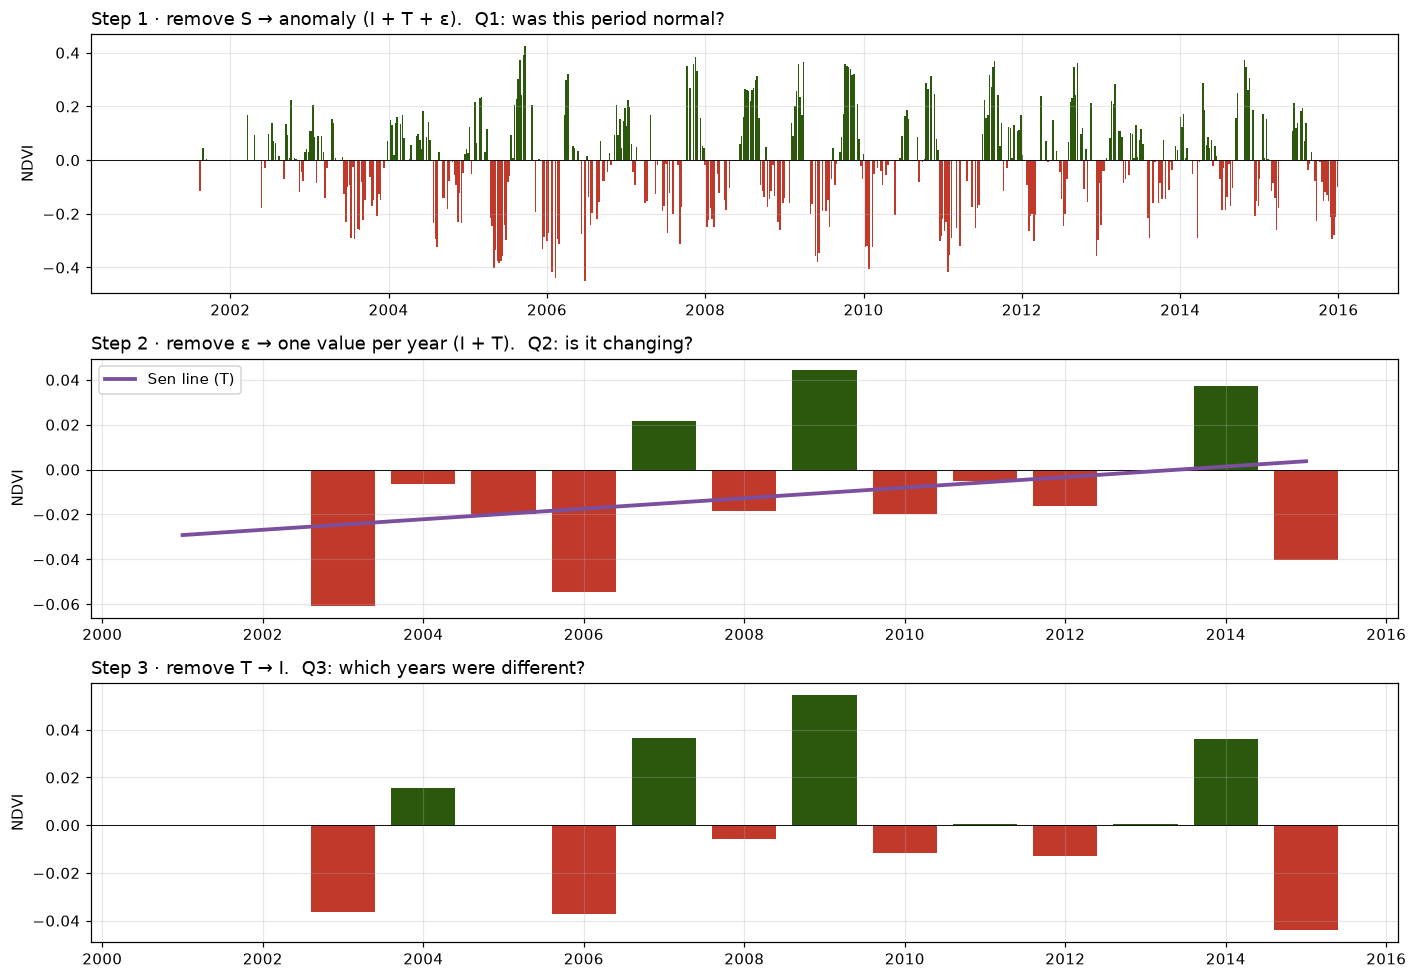

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9))
# table_to_series puts the table back in time order (2001 composite 1, 2001 composite 2, ...)
tt.bars(axes[0], dates, tt.table_to_series(anomaly_table), width=7)
axes[0].set_title("Step 1 · remove S → anomaly (I + T + ε).  Q1: was this period normal?", loc="left")
tt.bars(axes[1], yearly.index, yearly.values)
axes[1].plot(yearly.index, trend_line, color="#7B4F9E", lw=2.5, label="Sen line (T)")
axes[1].legend(); axes[1].set_title("Step 2 · remove ε → one value per year (I + T).  Q2: is it changing?", loc="left")
tt.bars(axes[2], yearly.index, I)
axes[2].set_title("Step 3 · remove T → I.  Q3: which years were different?", loc="left")
for ax in axes: ax.set_ylabel("NDVI")
plt.tight_layout(); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Which years were furthest below their trend in this pixel? Do they coincide with El Niño (2002–03, 2009–10, 2015)? (2) Is the slope of step 2 large compared with the year-to-year differences of step 3? What does that tell you about how easy it is to detect this trend?

### B2 · Mann–Kendall, by hand
The test compares **every pair** of values (an earlier one and a later one) and counts +1 if the later is larger, −1 if smaller:

$$ S = \sum_{i<j} \operatorname{sign}(x_j - x_i), \qquad \operatorname{Var}(S) = \frac{n(n-1)(2n+5)}{18}, \qquad Z = \frac{S - \operatorname{sign}(S)}{\sqrt{\operatorname{Var}(S)}} $$

Without a trend, $S$ is close to 0. A large $|Z|$ is unlikely by chance (small p-value). It uses only the **order** of the values, not their size, so one extreme year does not move it.

The example of the lecture: five years of peak NDVI.

In [21]:
x = np.array([0.60, 0.62, 0.61, 0.65, 0.64])      # five years of peak NDVI
n = len(x)                                        # number of years
S = 0
for i in range(n):                                # i = the earlier year
    for j in range(i + 1, n):                     # j = every LATER year (so each pair is counted once)
        # np.sign gives +1 if the later value is larger, -1 if it is smaller, 0 if equal
        sign = int(np.sign(x[j] - x[i]))
        S = S + sign                              # S adds up the +1 and -1 of all the pairs
        print(f"year {i + 1} -> year {j + 1}: {x[i]:.2f} -> {x[j]:.2f}   sign = {sign:+d}")
print("S =", S)

year 1 -> year 2: 0.60 -> 0.62   sign = +1
year 1 -> year 3: 0.60 -> 0.61   sign = +1
year 1 -> year 4: 0.60 -> 0.65   sign = +1
year 1 -> year 5: 0.60 -> 0.64   sign = +1
year 2 -> year 3: 0.62 -> 0.61   sign = -1
year 2 -> year 4: 0.62 -> 0.65   sign = +1
year 2 -> year 5: 0.62 -> 0.64   sign = +1
year 3 -> year 4: 0.61 -> 0.65   sign = +1
year 3 -> year 5: 0.61 -> 0.64   sign = +1
year 4 -> year 5: 0.65 -> 0.64   sign = -1
S = 6


In [22]:
var_S = n * (n - 1) * (2 * n + 5) / 18            # how much S varies by chance when there is no trend
# Z: how many standard deviations S is from 0 (the "- sign(S)" is a small continuity correction)
Z = (S - np.sign(S)) / np.sqrt(var_S)
print(f"Var(S) = {var_S:.2f}   Z = {Z:.2f}")
print("The toolbox:", tt.mann_kendall(x))

Var(S) = 16.67   Z = 1.22
The toolbox: {'n': 5, 'S': 6.0, 'var_S': 16.666666666666668, 'Z': 1.224744871391589, 'p': 0.22067136191984682, 'tau': 0.6, 'trend': 'no trend'}


**Four of five years go up, and the test says "no evidence of a trend" (p ≈ 0.22).** With five values, chance produces a pattern like this quite often: **a short series cannot prove a trend**, however convincing it looks.

### B3 · Sen's slope, by hand

$$ \beta = \operatorname{median}\left\{ \frac{x_j - x_i}{t_j - t_i} : i < j \right\} $$

where:

| Symbol | Meaning | In the example below |
|---|---|---|
| $\beta$ | **Sen's slope**: the typical change of the series per unit of time | NDVI per year |
| $x_i$, $x_j$ | the **values** of the series at two moments (e.g. the NDVI of two years) | 0.60, 0.62, … |
| $t_i$, $t_j$ | the **times** of those two values (e.g. the years, or 0, 1, 2, …) | years 1 to 5 |
| $i < j$ | every **pair** of moments, with $i$ the earlier and $j$ the later; each pair is counted once. With $n$ values there are $n(n-1)/2$ pairs | 5 values → 10 pairs |
| $\dfrac{x_j - x_i}{t_j - t_i}$ | the **slope of one pair**: how much the value changed, divided by the time between them (rise over run) | e.g. year 1 → 4: (0.65 − 0.60) / 3 = +0.017 |
| $\{\ \dots\ \}$ | the **set** of the slopes of all the pairs | 10 slopes |
| $\operatorname{median}$ | the value in the **middle** of that set once it is sorted | +0.0125 NDVI per year |

The **median** of the slopes of all pairs. Being a median, one extreme year barely moves it; a least-squares line can be tilted by one dry year at an end. Sen looks at the **same pairs** as Mann–Kendall (B2): Mann–Kendall keeps only the **sign** of each pair (is there a direction?), Sen keeps its **slope** (how much?).>

In [23]:
slopes = []                                         # an empty list, filled pair by pair
for i in range(n):
    for j in range(i + 1, n):
        slopes.append((x[j] - x[i]) / (j - i))          # change per year between year i and year j
print("The 10 slopes, sorted:", np.round(sorted(slopes), 3))
print("Sen slope = their median =", round(np.median(slopes), 4), "NDVI per year")

The 10 slopes, sorted: [-0.01  -0.01   0.005  0.007  0.01   0.015  0.015  0.017  0.02   0.04 ]
Sen slope = their median = 0.0125 NDVI per year


In [24]:
# Robustness: make the LAST year very dry, and compare with a least-squares line
x_dry = x.copy()                                    # a copy, so x does not change
x_dry[-1] = 0.45                                    # [-1] = the last element
# np.polyfit(x, y, 1) fits a straight line by least squares; [0] is its slope
least_squares = np.polyfit(np.arange(n), x_dry, 1)[0]
print(f"least-squares slope: {least_squares:+.4f}    Sen slope: {tt.sens_slope(x_dry)['slope']:+.4f}")

least-squares slope: -0.0270    Sen slope: -0.0025


### B4 · An experiment: how often does the test lie?
At α = 0.05 the test should find a "trend" in **5 %** of series that have none. That promise holds only if the values are **independent**. NDVI values are not: each one resembles the previous one (**autocorrelation**), and wet and dry years shift all the composites of a year together.

The toolbox generates 300 synthetic series **without any trend** (15 years) and counts how many each method calls significant:

* **original**: Mann–Kendall on all the anomalies (15 × 23 = 345 values);
* **Hamed–Rao**: the same, with the variance of S corrected for autocorrelation (Hamed & Rao, 1998);
* **annual**: Mann–Kendall on one mean per year (15 values) — **step 2 of B1**.

⏳ About a minute.

In [35]:
# ---------------------------------------------------------------------------
# B4 · How often does Mann–Kendall find a trend that is NOT there?
# ---------------------------------------------------------------------------
# A "false positive" is a series with NO real trend that the test nevertheless
# calls significant (p < 0.05). By choosing alpha = 0.05 we accept that this will
# happen in about 5 % of trend-free series, but ONLY if the values are independent.
# Here we check whether that promise holds when they are not.
#
# Each call to tt.false_positive_experiment:
#   1. generates 300 synthetic NDVI series of 15 years (one composite every 16 days,
#      i.e. 23 per year), all of them WITHOUT any trend;
#   2. tests each series with three methods:
#        "original"  -> Mann–Kendall on all the anomalies (15 x 23 = 345 values)
#        "Hamed-Rao" -> the same, with Var(S) corrected for autocorrelation
#        "annual"    -> Mann–Kendall on one mean value per year (15 values, step 2 of B1)
#   3. returns, for each method, the SHARE of the 300 series it called significant.
# Since none of the series has a trend, every "significant" result is a false alarm:
# a method that keeps its promise should give about 0.05.
#
# The three situations differ only in how the noise is built:

# 1) INDEPENDENT (ar1 = 0.0): each value is drawn on its own, with no memory of the
#    previous one. Knowing that one composite was high tells you nothing about the next.
#    This is the ideal case that the test assumes: all three methods should give ~0.05.
independent = tt.false_positive_experiment(ar1=0.0)

# 2) AUTOCORRELATED (ar1 = 0.6): each value "remembers" the previous one. The noise of
#    a composite is 0.6 x the noise of the previous composite plus a new random part,
#    so a high value tends to be followed by another high value (as real NDVI does:
#    vegetation does not change much in 16 days). Neighbouring values are partly copies
#    of each other, so the 345 values carry much less information than 345 independent
#    ones. The original test does not know this, believes it has more evidence than it
#    has, and calls "trend" too often.
autocorrelated = tt.false_positive_experiment(ar1=0.6)

# 3) AUTOCORRELATED + WET/DRY YEARS (ar1 = 0.6, interannual = 0.02): as in 2), and in
#    addition each year is shifted up or down as a whole, by a random amount with a
#    standard deviation of 0.02 NDVI. This imitates wet years (all composites a little
#    higher) and dry years (all a little lower), such as La Niña and El Niño. For a test
#    on all the composites, a dry year looks like 23 low values in a row, a run that the
#    test reads as evidence of change. It acts like a stronger, longer autocorrelation.
with_years = tt.false_positive_experiment(ar1=0.6, interannual=0.02)

# Put the three results in one table: one ROW per situation, one COLUMN per method.
# Each dictionary becomes a column of the DataFrame, and .T (transpose) swaps rows and
# columns so that the situations are the rows.
result = pd.DataFrame({"independent": independent,
                       "autocorrelated": autocorrelated,
                       "autocorrelated + wet/dry years": with_years}).T
print("Share of series WITHOUT trend called significant (the promise is 0.05):")
print(result.round(3))
# How to read it: values close to 0.05 = the method keeps its promise;
# values well above 0.05 = the method "invents" trends that are not there.

Share of series WITHOUT trend called significant (the promise is 0.05):
                                original  Hamed-Rao  annual
independent                        0.067      0.060   0.073
autocorrelated                     0.383      0.177   0.077
autocorrelated + wet/dry years     0.580      0.313   0.063


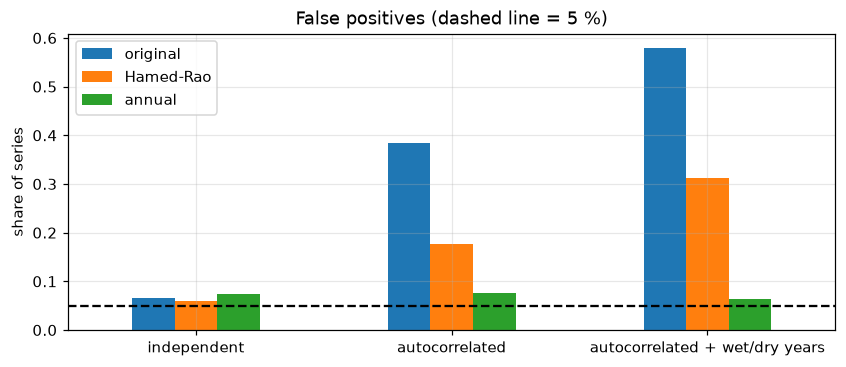

In [26]:
result.plot(kind="bar", figsize=(9, 3.5), rot=0, title="False positives (dashed line = 5 %)")
plt.axhline(0.05, color="k", ls="--"); plt.ylabel("share of series"); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Which method keeps its promise in each situation? Why do wet and dry years act like autocorrelation for a test on all the composites? (2) The next cell repeats the experiment with series that DO have a real trend of 0.003 NDVI per year (`trend=0.003`). Which method detects it most often? What does the annual method lose in exchange for its honesty?

*The next cell does the computation the question needs: run it, and use its result in your answer.*

In [28]:
print(tt.false_positive_experiment(ar1=0.6, interannual=0.02, trend=0.003, n_series=200))

{'original': 0.92, 'Hamed-Rao': 0.785, 'annual': 0.445}


### B5 · One pixel, three defensible routes

**The question:** *is the NDVI of this pixel changing over the years, and can we say so without fooling ourselves?*

B1–B3 gave us the tools (Mann–Kendall: *is there a trend?*; Sen: *how much?*), and B4 warned that Mann–Kendall on all the composites **invents trends** unless it is corrected or the data are averaged first. To answer the question honestly, any route has to solve two problems:

1. **The seasonal cycle gets in the way:** it is much larger than the trend, and comparing a peak with a trough looks like a "decrease".
2. **The values resemble each other** (autocorrelation, wet and dry years): the test believes it has more evidence than it has.

B5 applies this to a real pixel with **three defensible routes**, three different ways of solving those two problems. All three report Sen's slope and a Mann–Kendall p-value; they differ in **how they handle the seasonal cycle** and **how many values they test**.

| Route | The seasonal cycle is… | Values | Weak point |
|---|---|---|---|
| **1 · Anomalies + Hamed–Rao** | **removed** (observed − climatology) | all composites, with Var(S) corrected for autocorrelation | a change in the timing of the season (the rice trap, A13) stays in the anomalies |
| **2 · Seasonal Mann–Kendall** | **avoided**: each composite is compared only with the same composite in other years | all composites, column by column | still affected by autocorrelation between years |
| **3 · Annual means** | **averaged away** (step 2 of B1) | 15, one per year | little **power**: small real trends are often missed (B4) |

Slopes are printed in **NDVI per decade**. In route 1 Sen's slope comes per composite (8 days), so it is multiplied by $P = 46$ to give a yearly slope.

**Why three routes and not one?** None is perfect, so comparing them tells us **how much to trust the answer**:
same sign and all significant → a **robust** trend. Same sign, different significance → report it and say which route you used (B4 explains why they differ). Different signs → **do not claim a trend**.

> 💡 The aim of the routes: **not to claim a trend that is not there, and not to miss one that is.** A credible trend is one that survives several reasonable routes.

In [30]:
name = "seasonal crop"                                        # try also the other two pixels
table = TABLES[name]

# Route 1 - anomalies of every composite + Hamed-Rao correction
# climatology -> anomalies (table) -> one long series of 690 values
anomaly_series = tt.table_to_series(tt.anomalies(table, tt.climatology(table, REF_YEARS)))
r1 = tt.mann_kendall_hamed_rao(anomaly_series)                  # test corrected for autocorrelation
# the slope comes per composite (one step = 8 days); x 46 converts it to per year
slope1 = tt.sens_slope(anomaly_series)["slope"] * P
print(f"Route 1, anomalies + Hamed-Rao: slope {10 * slope1:+.3f} NDVI/decade, p = {r1['p']:.3f}")

Route 1, anomalies + Hamed-Rao: slope +0.007 NDVI/decade, p = 0.651


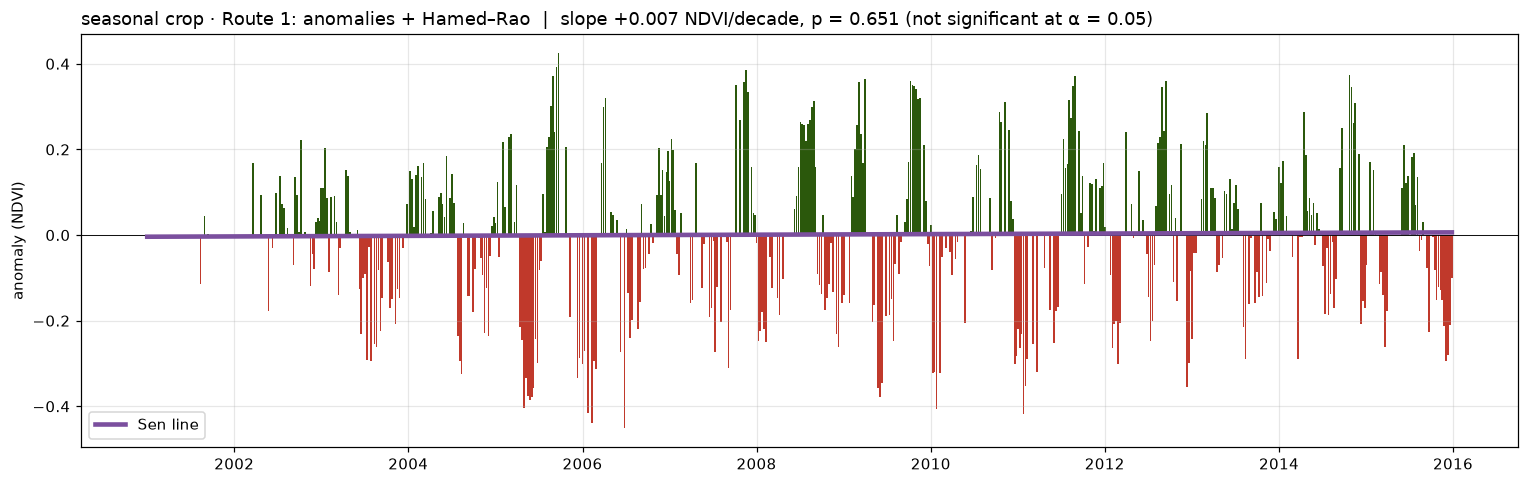

In [31]:
# ---------------------------------------------------------------------------
# Route 1 in a figure: the anomalies of every composite and their Sen line
# ---------------------------------------------------------------------------
# The test above gives two numbers (the slope and p). Here we draw what is
# behind them: the anomaly of each composite in time order, and the straight
# line whose slope Sen's method has estimated.

# Sen's slope again, this time keeping the intercept as well, so the line can be drawn.
# With no times given, sens_slope uses the position of each value: 0, 1, 2, ... (one step = one composite).
line1 = tt.sens_slope(anomaly_series)
step = np.arange(len(anomaly_series))                       # 0, 1, 2, ..., 689: the position of each composite
sen_line = line1["intercept"] + line1["slope"] * step       # the value of the line at each composite

d = dates[:len(anomaly_series)]                             # one date per value, in the same order

fig, ax = plt.subplots(figsize=(14, 4.5))

# The anomalies as bars: green above normal, red below normal
tt.bars(ax, d, anomaly_series, width=7)

# The Sen line on top. Its slope is tiny compared with the bars, so a thick line helps to see it.
ax.plot(d, sen_line, color="#7B4F9E", lw=3, label="Sen line")

# The result of the test in the title: slope per decade and the Hamed–Rao p-value
verdict = "significant" if r1["p"] < 0.05 else "not significant"
ax.set_title(f"{name} · Route 1: anomalies + Hamed–Rao  |  slope {10 * slope1:+.3f} NDVI/decade, "
             f"p = {r1['p']:.3f} ({verdict} at α = 0.05)", loc="left")
ax.set_ylabel("anomaly (NDVI)")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

# How to read it: the bars are I + T + ε (Part A, step 1). The line is T. If the line is almost
# flat compared with the bars, the trend is small next to the year-to-year variation; the p-value
# says whether, even so, it is unlikely to be chance once autocorrelation is taken into account.

In [32]:
# Route 2 - seasonal Mann-Kendall: composite 1 is compared only with composite 1 of other years, etc.
#           A peak is never compared with a trough, so the seasonal cycle does not need to be removed.
r2 = tt.seasonal_mann_kendall(table)
print(f"Route 2, seasonal Mann-Kendall: slope {10 * r2['slope']:+.3f} NDVI/decade, p = {r2['p']:.3f}")

Route 2, seasonal Mann-Kendall: slope +0.006 NDVI/decade, p = 0.624


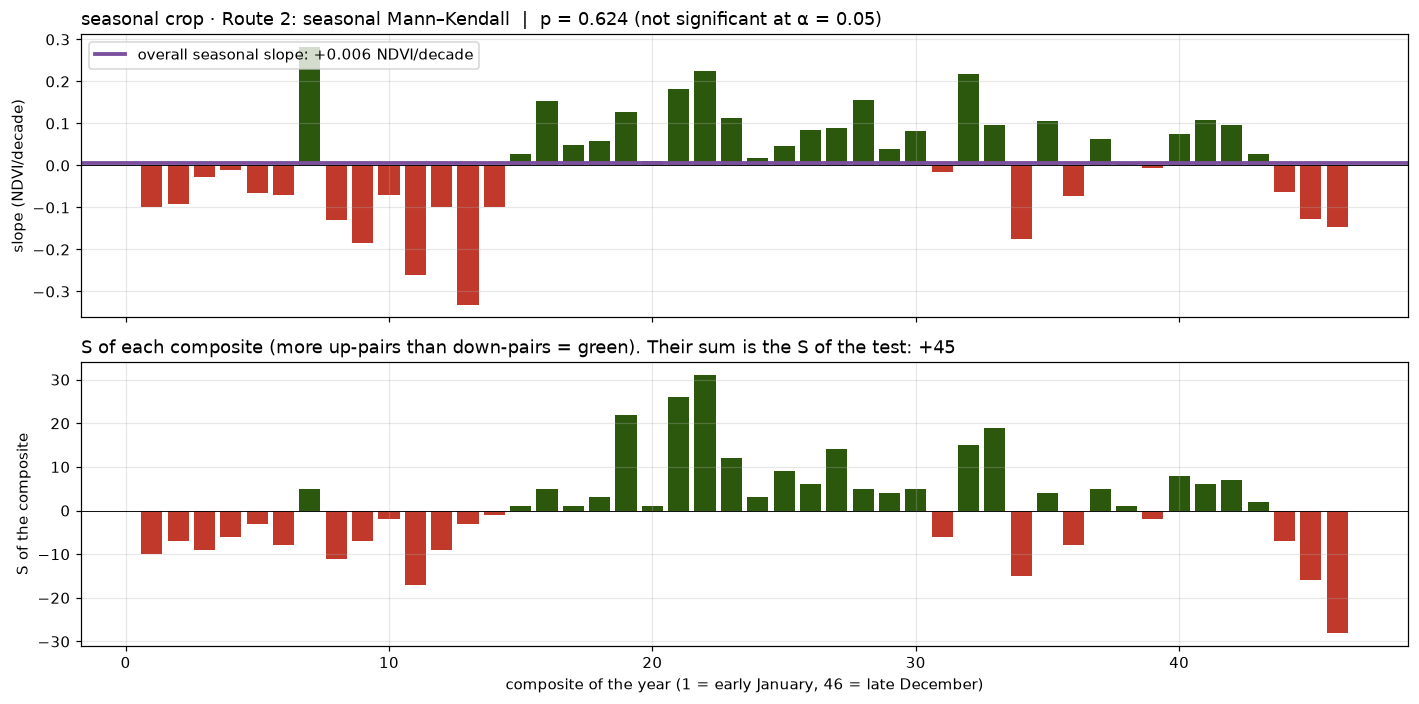

In [34]:
# ---------------------------------------------------------------------------
# Route 2 in a figure: what the seasonal Mann–Kendall does, composite by composite
# ---------------------------------------------------------------------------
# The seasonal test does NOT test the whole series at once. It takes each COLUMN of the
# years x composites table (composite 1 of every year, composite 2 of every year, ...),
# runs a small Mann–Kendall and a Sen slope on that column alone, and then:
#   - adds up the 46 values of S and of Var(S) to get one Z and one p-value;
#   - takes the median of ALL the pairwise slopes of all the columns as the overall slope.
# Here we repeat the column-by-column part so that we can see it.

years = table.index.values                     # 2001, 2002, ..., 2015
col_slope, col_S, col_n = [], [], []           # one value per composite
for p in table.columns:                        # p = 1, 2, ..., 46
    col = table[p].values                      # composite p in every year (15 values, some NaN)
    ok = ~np.isnan(col)                        # years with data in this composite
    col_n.append(ok.sum())
    if ok.sum() < 3:                           # with fewer than 3 years there is no test (as in the toolbox)
        col_slope.append(np.nan); col_S.append(np.nan)
        continue
    col_slope.append(tt.sens_slope(col[ok], years[ok])["slope"])   # NDVI per year, this composite only
    col_S.append(tt.mann_kendall(col[ok])["S"])                     # how many pairs go up minus go down

col_slope = np.array(col_slope)
col_S = np.array(col_S)

fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)

# --- Top: the Sen slope of each composite, and the overall seasonal slope ---
tt.bars(axes[0], table.columns, 10 * col_slope)                      # per decade, green up, red down
axes[0].axhline(10 * r2["slope"], color="#7B4F9E", lw=2.5,
                label=f"overall seasonal slope: {10 * r2['slope']:+.3f} NDVI/decade")
axes[0].set_ylabel("slope (NDVI/decade)")
axes[0].legend(loc="upper left")
verdict = "significant" if r2["p"] < 0.05 else "not significant"
axes[0].set_title(f"{name} · Route 2: seasonal Mann–Kendall  |  p = {r2['p']:.3f} ({verdict} at α = 0.05)",
                  loc="left")

# --- Bottom: the S of each composite. The test adds these 46 numbers together ---
tt.bars(axes[1], table.columns, col_S)
axes[1].set_ylabel("S of the composite")
axes[1].set_xlabel("composite of the year (1 = early January, 46 = late December)")
axes[1].set_title(f"S of each composite (more up-pairs than down-pairs = green). "
                  f"Their sum is the S of the test: {r2['S']:+.0f}", loc="left")

plt.tight_layout(); plt.show()

# How to read it: if most bars point the same way, the trend appears at every time of year
# and the seasonal test will be confident. If some composites go up and others go down
# (for example, earlier sowing raises May and lowers July), they cancel in the sum: the
# seasonal test then sees little trend, even though the season has clearly changed.

In [36]:
# Route 3 - one mean value per year (step 2 of B1)
annual = tt.annual_aggregate(table, "mean", min_share=0.6)        # one mean NDVI per year (15 values)
r3 = tt.mann_kendall_hamed_rao(annual.values)
slope3 = tt.sens_slope(annual.values, annual.index.values)["slope"]
print(f"Route 3, annual means         : slope {10 * slope3:+.3f} NDVI/decade, p = {r3['p']:.3f}")

Route 3, annual means         : slope +0.026 NDVI/decade, p = 0.300


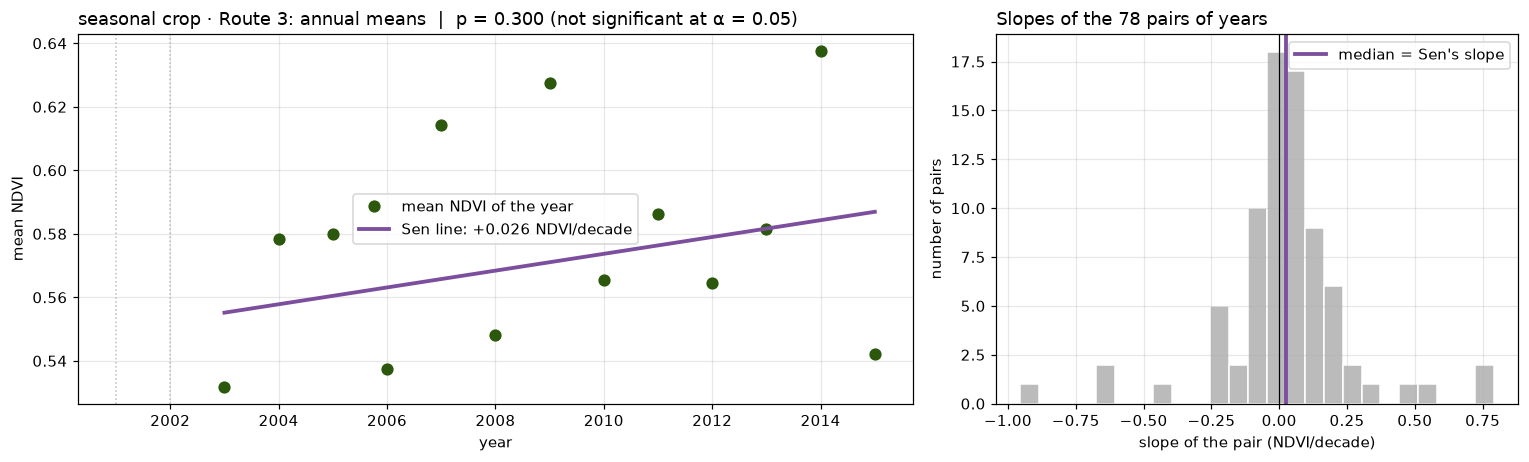

In [38]:
# ---------------------------------------------------------------------------
# Route 3 in a figure: one mean per year, its Sen line, and where the slope comes from
# ---------------------------------------------------------------------------
# Route 3 summarises each year in ONE value (its mean NDVI), so the seasonal cycle
# disappears inside the mean and the 15 values are almost independent (B4).
# The trend is then tested on those 15 values only.

line3 = tt.sens_slope(annual.values, annual.index.values)    # slope AND intercept, in NDVI per year
kept = ~np.isnan(annual.values)                               # years with enough data (min_share = 0.6)
yrs = annual.index.values[kept]                               # those years
vals = annual.values[kept]                                    # their mean NDVI
sen_line = line3["intercept"] + line3["slope"] * yrs          # the value of the Sen line in each year

# Every pair of years (earlier i, later j) and its slope: the raw material of Sen's method
i, j = np.triu_indices(len(vals), k=1)                        # all index pairs with i < j
pair_slopes = (vals[j] - vals[i]) / (yrs[j] - yrs[i])         # NDVI per year, one per pair

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.6, 1]})

# --- Left: the yearly means and the Sen line ---
axes[0].plot(yrs, vals, "o", ms=7, color="#2B580C", label="mean NDVI of the year")
axes[0].plot(yrs, sen_line, color="#7B4F9E", lw=2.5,
             label=f"Sen line: {10 * slope3:+.3f} NDVI/decade")
for y in annual.index.values[~kept]:                          # mark the years left out for lack of data
    axes[0].axvline(y, color="#BBBBBB", ls=":", lw=1)
verdict = "significant" if r3["p"] < 0.05 else "not significant"
axes[0].set_title(f"{name} · Route 3: annual means  |  p = {r3['p']:.3f} ({verdict} at α = 0.05)",
                  loc="left")
axes[0].set_xlabel("year"); axes[0].set_ylabel("mean NDVI")
axes[0].legend(loc="best")

# --- Right: the slopes of all the pairs; their MEDIAN is Sen's slope ---
axes[1].hist(10 * pair_slopes, bins=25, color="#BBBBBB", edgecolor="white")
axes[1].axvline(10 * slope3, color="#7B4F9E", lw=2.5, label="median = Sen's slope")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title(f"Slopes of the {len(pair_slopes)} pairs of years", loc="left")
axes[1].set_xlabel("slope of the pair (NDVI/decade)"); axes[1].set_ylabel("number of pairs")
axes[1].legend(loc="upper right")

plt.tight_layout(); plt.show()

# How to read it: on the left, few points and a lot of scatter around the line is the price
# of this route (little power). On the right, the share of pairs to the right of zero is what
# Mann–Kendall counts (pairs going up); the purple line is the size of the change (Sen).

The slopes are in **NDVI per decade** (per year × 10).

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. Do the three routes agree on the **sign**? On significance? If they disagree, which one would you report, and what would you write next to it?

#### The three routes side by side

Each route has given two numbers for the same pixel: **Sen's slope** (how much the NDVI changes, in NDVI per decade) and a **Mann–Kendall p-value** (how likely such a trend would be by chance). The next figure puts them together so we can answer the question of B5 at a glance:

* **Left panel · the slopes.** Do the three routes agree on the **sign** (all up or all down) and roughly on the **size**?
* **Right panel · the p-values.** Bars to the left of the dashed line (p < 0.05) are **significant**. Do the routes agree on significance?

Remember why they may differ: route 1 uses every composite (more power, but a change in the timing of the season stays in the anomalies); route 2 compares each composite only with itself (a change that raises one season and lowers another cancels out); route 3 uses only 15 values (honest, but little power, as in B4).

| What you see | What you conclude |
|---|---|
| Same sign, all significant | a **robust** trend |
| Same sign, only some significant | a trend that depends on the route: report it and say which route you used |
| Different signs | **do not claim a trend** |

                    route  slope_decade      p  significant
1 · Anomalies + Hamed–Rao        0.0068 0.6510        False
2 · Seasonal Mann–Kendall        0.0060 0.6243        False
         3 · Annual means        0.0265 0.2997        False


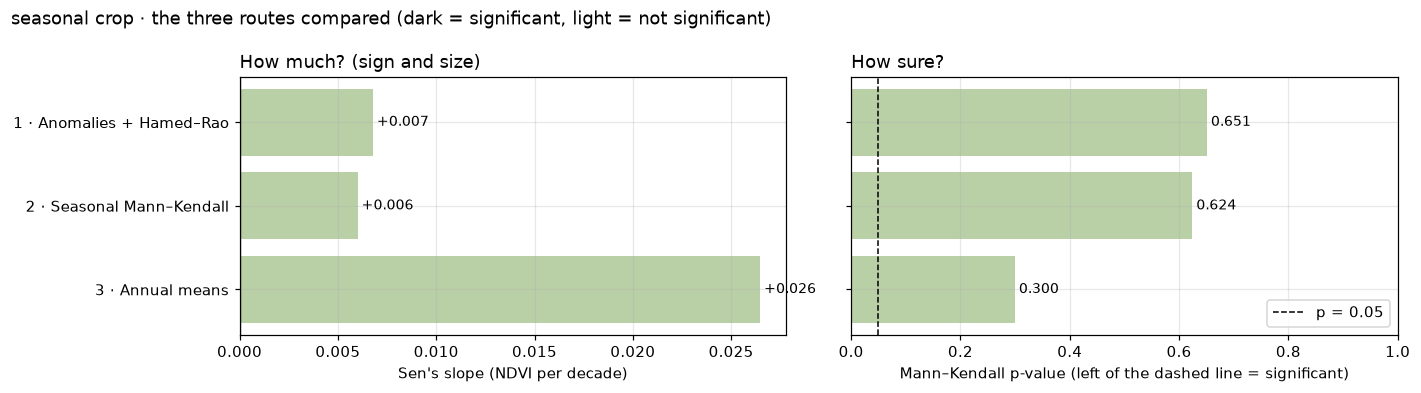

Verdict: same sign, but no route is significant -> no evidence of a trend.


In [39]:
# ---------------------------------------------------------------------------
# The three routes side by side: slope (how much) and p-value (how sure)
# ---------------------------------------------------------------------------
# We collect the results of the three cells above in one table, then draw two panels:
# the Sen slopes on the left and the Mann–Kendall p-values on the right.

routes = pd.DataFrame({
    "route": ["1 · Anomalies + Hamed–Rao", "2 · Seasonal Mann–Kendall", "3 · Annual means"],
    "slope_decade": [10 * slope1, 10 * r2["slope"], 10 * slope3],   # NDVI per decade (per year x 10)
    "p": [r1["p"], r2["p"], r3["p"]],
})
routes["significant"] = routes["p"] < 0.05                            # True if p < 0.05
print(routes.round(4).to_string(index=False))

# Colours: dark when significant, light when not, so the eye reads significance in both panels
colour = ["#2B580C" if s else "#B9CFA6" for s in routes["significant"]]
ypos = np.arange(len(routes))[::-1]                                   # route 1 at the top

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)

# --- Left: Sen slope of each route (NDVI per decade) ---
axes[0].barh(ypos, routes["slope_decade"], color=colour)
axes[0].axvline(0, color="k", lw=0.8)                                 # zero = no change
for y, v in zip(ypos, routes["slope_decade"]):
    axes[0].text(v, y, f" {v:+.3f} ", va="center",
                 ha="left" if v >= 0 else "right", fontsize=9)       # the value next to each bar
axes[0].set_yticks(ypos); axes[0].set_yticklabels(routes["route"])
axes[0].set_xlabel("Sen's slope (NDVI per decade)")
axes[0].set_title("How much? (sign and size)", loc="left")

# --- Right: p-value of each route, with the 0.05 threshold ---
axes[1].barh(ypos, routes["p"], color=colour)
axes[1].axvline(0.05, color="k", ls="--", lw=1, label="p = 0.05")
for y, v in zip(ypos, routes["p"]):
    axes[1].text(v, y, f" {v:.3f}", va="center", ha="left", fontsize=9)
axes[1].set_xlim(0, max(1.0, routes["p"].max() * 1.15))
axes[1].set_xlabel("Mann–Kendall p-value (left of the dashed line = significant)")
axes[1].set_title("How sure?", loc="left")
axes[1].legend(loc="lower right")

fig.suptitle(f"{name} · the three routes compared (dark = significant, light = not significant)",
             x=0.01, ha="left")
plt.tight_layout(); plt.show()

# A one-line verdict, following the table in the markdown cell above
signs = np.sign(routes["slope_decade"])
if signs.nunique() > 1:
    print("Verdict: the routes disagree on the SIGN -> do not claim a trend.")
elif routes["significant"].all():
    print("Verdict: same sign and all significant -> a robust trend.")
elif routes["significant"].any():
    print("Verdict: same sign, but only some routes are significant -> report it and say which route you used.")
else:
    print("Verdict: same sign, but no route is significant -> no evidence of a trend.")

### B6 · Two checks: the edges, and a slope that changes

**Why check?** B5 gave one slope and one p-value for the whole period 2001–2015. That single number hides two assumptions: that the result does not depend on **where the series starts and ends**, and that the change has gone **in the same direction all the time**. B6 tests both, using the annual means of route 3.

**Check 1 · The edges.** Sen and Mann–Kendall compare every pair of years, and the pairs that span the longest time (the first years against the last ones) weigh a lot in the result. If the series happens to start in a wet year (La Niña) and end in a dry one (El Niño), it can show a "trend" that only reflects those two extremes. So we remove one or two years at the start and/or the end and test again:

| Period | What it checks |
|---|---|
| 2001–2015 | the full series (the result of B5) |
| 2002–2015 / 2001–2014 | without the first / the last year |
| 2002–2014 / 2003–2013 | without one / two years at each end |

**How to read it:** if the **sign** of the slope stays the same in every period, the trend does not depend on the edges. If it changes sign, or the p-value jumps from significant to not significant, the "trend" was driven by one or two years at an end.

**Check 2 · Rolling Sen slope.** One slope for 15 years assumes the change has gone in the same direction all the time. But NDVI can rise for some years and fall for others (a change of land use, a drought followed by a recovery), and a single slope would average them into something that describes neither. So we compute Sen's slope in **windows of 8 years** that move one year at a time (2001–2008, 2002–2009, …) and draw each slope at the **central year** of its window.

**How to read it:** if the curve stays on one side of zero, the direction has been **constant**. If it **crosses zero**, the direction **changed**, and one slope for the whole period is not a good summary. The window length is a choice: a short window follows wet and dry years (noisy), a long window is smoother but gives fewer slopes.

> ⚠️ These are **descriptive checks**, not new tests: with 8 values per window, a single rolling slope is not significant on its own. They tell us how much to trust the slope of B5.

In [ ]:
# ---------------------------------------------------------------------------
# Check 1 · The edges: does the trend depend on the first or last years?
# ---------------------------------------------------------------------------
# We repeat the test of route 3 (annual means) on shorter periods, removing one or
# two years at the start and/or the end. If the sign of the slope (and roughly its
# significance) stays the same, the trend does not hinge on the edges of the series.
#
# Each item of the list is a (first year, last year) pair:
#   (2001, 2015) -> the full series, the same result as route 3 in B5
#   (2002, 2015) -> without the first year
#   (2001, 2014) -> without the last year
#   (2002, 2014) -> without one year at each end
#   (2003, 2013) -> without two years at each end
for first, last in [(2001, 2015), (2002, 2015), (2001, 2014), (2002, 2014), (2003, 2013)]:

    # annual is a pandas Series indexed by year (one mean NDVI per year, from route 3).
    # .loc[first:last] keeps the years from first to last, BOTH included
    # (unlike Python lists, .loc on labels includes the end).
    part = annual.loc[first:last]

    # Sen's slope of that period: x = the yearly means, t = the years.
    # It comes in NDVI per year; it is multiplied by 10 in the print to give NDVI per decade.
    s = tt.sens_slope(part.values, part.index.values)["slope"]

    # Mann–Kendall with the Hamed–Rao correction on the same period: is the trend unlikely to be chance?
    p_value = tt.mann_kendall_hamed_rao(part.values)["p"]

    # One line per period: compare the SIGN of the slope and whether p stays below 0.05
    print(f"{first}-{last}: slope {10 * s:+.3f} NDVI/decade, p = {p_value:.3f}")

# How to read it: the same sign in every line -> the trend is not an effect of the edges.
# A change of sign, or p jumping above or below 0.05 when one year is removed, means that
# one or two years at an end (often an El Niño or La Niña year) were driving the result.
# Note that shorter periods have fewer years, so p tends to rise a little anyway (less power).

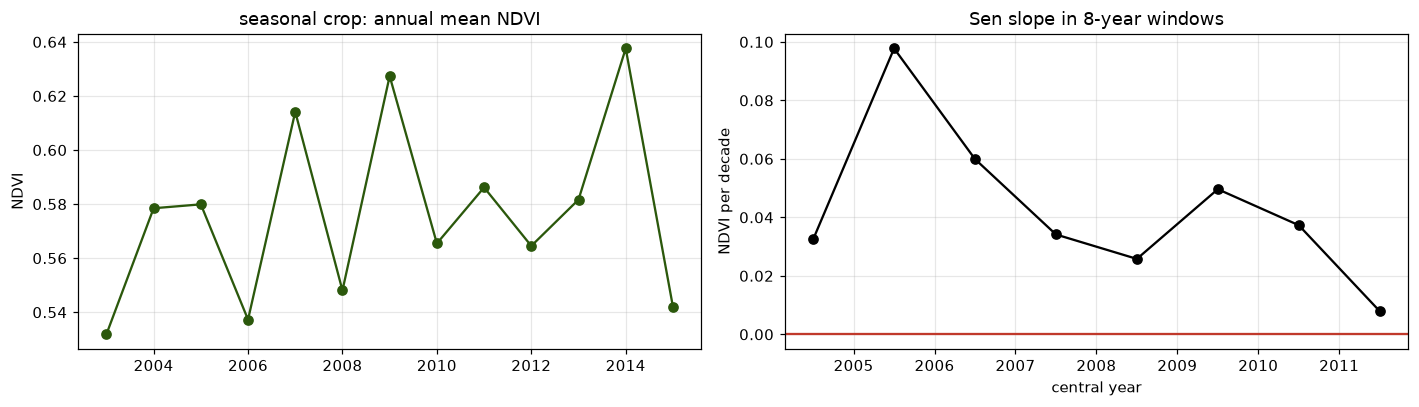

In [40]:
# One Sen slope per 8-year window (2001-2008, 2002-2009, ...), drawn at the central year of the window
rolling = tt.rolling_sen(annual, window=8)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(annual.index, annual.values, "o-", color=COLOURS[name])
axes[0].set_title(f"{name}: annual mean NDVI"); axes[0].set_ylabel("NDVI")
axes[1].plot(rolling.index, 10 * rolling.values, "o-", color="k")
axes[1].axhline(0, color="#C0392B")
axes[1].set_title("Sen slope in 8-year windows"); axes[1].set_xlabel("central year"); axes[1].set_ylabel("NDVI per decade")
plt.tight_layout(); plt.show()

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Does the sign survive when you remove years at the ends? (2) The next cell repeats the rolling slope with windows of 6, 8 and 10 years: what do you gain and lose with a shorter or a longer window?

*The next cell does the computation the question needs: run it, and use its result in your answer.*

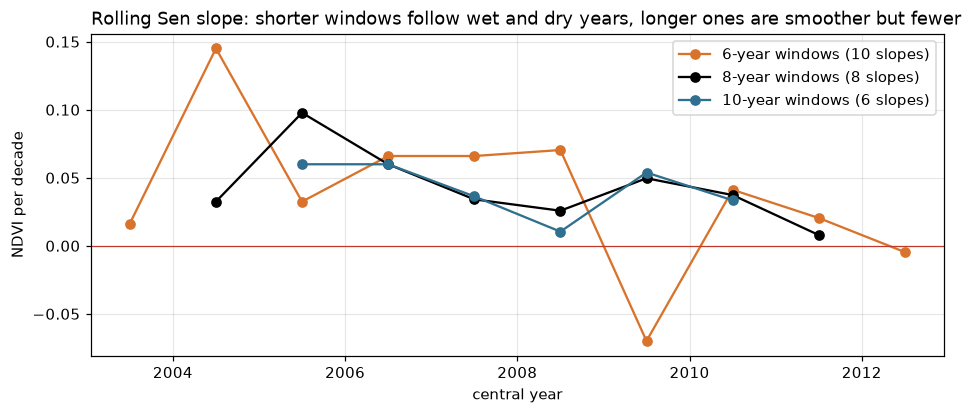

In [41]:
# The rolling Sen slope with three window lengths: 6, 8 and 10 years
fig, ax = plt.subplots(figsize=(10, 3.8))
for window, colour in [(6, "#D9732B"), (8, "k"), (10, "#2F6F8F")]:
    r_w = tt.rolling_sen(annual, window=window)               # one slope per window, at its central year
    ax.plot(r_w.index, 10 * r_w.values, "o-", color=colour, label=f"{window}-year windows ({len(r_w)} slopes)")
ax.axhline(0, color="#C0392B", lw=0.8)
ax.set_xlabel("central year"); ax.set_ylabel("NDVI per decade")
ax.set_title("Rolling Sen slope: shorter windows follow wet and dry years, longer ones are smoother but fewer", loc="left")
ax.legend(); plt.show()

### B7 · A map of trends, and the problem of thousands of tests
We test **every pixel** with route 3 (annual means, Hamed–Rao). With α = 0.05 and **no trend anywhere**, about 5 % of the pixels would still look "significant", and since neighbouring pixels resemble each other, those false positives form **patches that look real**.

The remedy: control the **False Discovery Rate** (Benjamini & Hochberg, 1995). Sort the p-values and accept only those with $p_{(k)} \le (k/m)\,\alpha$. Wilks (2016) recommends $\alpha_{FDR} = 0.10$ for maps. ⏳ One or two minutes.

In [42]:
# One mean NDVI per pixel and year: a cube of (15 years, rows, columns)
annual_cube, years = tt.annual_mean_cube(ndvi, dates, min_share=0.6, steps_per_year=P)
# For EVERY pixel: Sen slope and Mann-Kendall p-value (Hamed-Rao); pixels with < 10 valid years are left NaN
slope, pval = tt.trend_map(annual_cube, years, method="hamed_rao", min_years=10)

tested = np.isfinite(pval).sum()                      # how many pixels were tested
naive = pval < 0.05                                   # True/False map without correction
fdr = tt.fdr_mask(pval, alpha=0.10)                   # True/False map after the FDR correction (Benjamini-Hochberg)
print("pixels tested:", tested)
print("'significant' with p < 0.05:", naive.sum(), f"({100 * naive.sum() / tested:.1f} %)")
print("significant after FDR:     ", fdr.sum(), f"({100 * fdr.sum() / tested:.1f} %)")
print("expected by chance alone if nothing changed: about", round(0.05 * tested))

pixels tested: 6472
'significant' with p < 0.05: 981 (15.2 %)
significant after FDR:      67 (1.0 %)
expected by chance alone if nothing changed: about 324


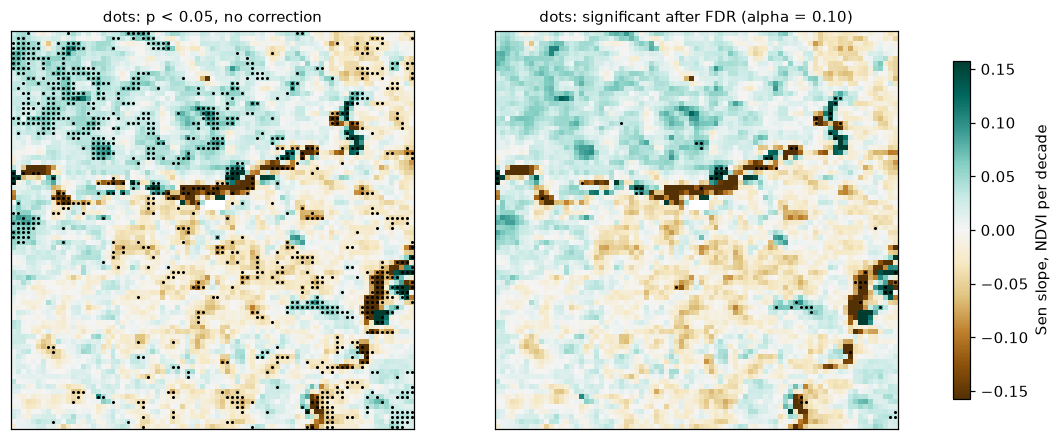

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# colour = Sen slope per decade (brown = decreasing, green = increasing); black dots = "significant" pixels
im = tt.show_trend_map(axes[0], slope, title="dots: p < 0.05, no correction", mask=naive)
tt.show_trend_map(axes[1], slope, pval, title="dots: significant after FDR (alpha = 0.10)")
plt.colorbar(im, ax=axes, shrink=0.8, label="Sen slope, NDVI per decade")
plt.show()

**How to report a map of trends:** the Sen slope in a colour scale centred on zero (NDVI per decade); dots only where the trend is significant **after** the correction; and in the legend: method, period, aggregation, autocorrelation correction and the α of the FDR.

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Where are the significant pixels after FDR? Do they match a land cover you recognise? (2) Give three reasons why a significant pixel might still not be a real change in vegetation.

### B8 · A slope or a step?
Mann–Kendall asks whether the series is **monotonic**. It cannot tell a slow change from a **step** in one year (a paddy turned into housing, a new canal, an uncorrected change of processing).

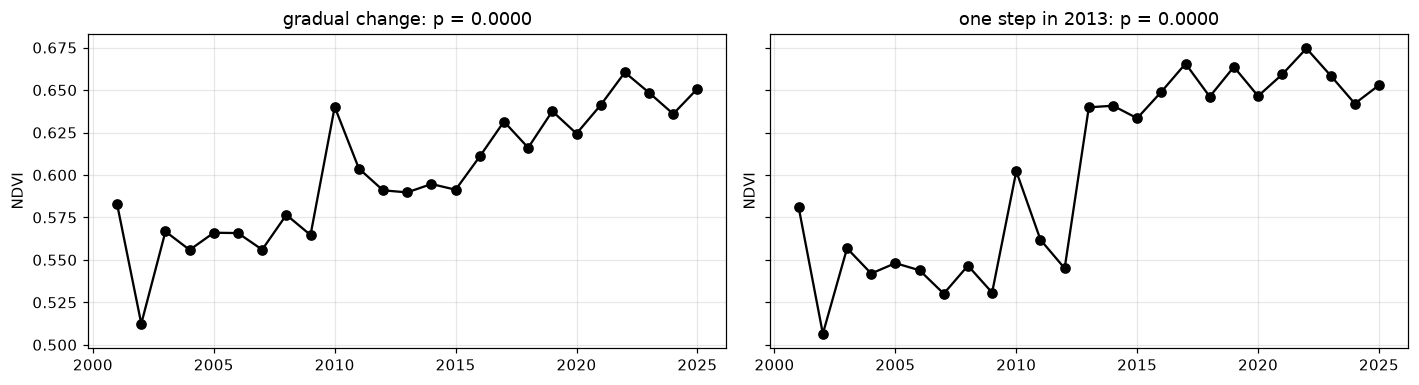

In [44]:
# Two synthetic series without seasonal cycle (amplitude=0): a slow rise, and a jump of 0.1 in 2013
gradual = tt.synthetic_ndvi(trend_per_year=0.004, amplitude=0, interannual=0.015, noise=0.02, seed=3)
step = tt.synthetic_ndvi(trend_per_year=0.0, amplitude=0, interannual=0.015, noise=0.02, step_year=2013, step_size=0.1, seed=3)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, label, d in [(axes[0], "gradual change", gradual), (axes[1], "one step in 2013", step)]:
    yearly_mean = d.groupby("year")["value"].mean()          # one mean value per year
    p_value = tt.mann_kendall(yearly_mean.values)["p"]
    ax.plot(yearly_mean.index, yearly_mean.values, "o-", color="k")
    ax.set_title(f"{label}: p = {p_value:.4f}"); ax.set_ylabel("NDVI")
plt.tight_layout(); plt.show()

Both are "significant increasing trends" for Mann–Kendall. Only **looking at the series**, or a method that searches for **breakpoints** (BFAST, Verbesselt et al., 2010), can tell them apart. Forkel et al. (2013): finding **too many** breakpoints is worse than too few; accept one when it coincides with something known.

### B9 · Two sensors, two periods: Sentinel-2 and MODIS
Sentinel-2 sees each paddy (20 m) but only since about 2017; MODIS mixes paddies and roads (250 m) but has a long record. To compare them over the **same years** we use two small files for the window of Session 1 (3.6 × 3.6 km): monthly **Sentinel-2 2018–2025** and **MODIS 2018–2025**. If the files are not in your folder, the functions build them once (⏳ Sentinel-2 takes several minutes per year).

Three maps with the same method:
* same years, different sensor → the effect of **resolution**;
* same sensor, different period (MODIS 2001–2015 vs 2018–2025) → a trend **belongs to its period**.

In [ ]:
# [west, south, east, north]: the 3.6 x 3.6 km window of Session 1 (0.0163 degrees ≈ 1.8 km each way)
S2_BBOX = [-74.985 - 0.0163, 3.915 - 0.0163, -74.985 + 0.0163, 3.915 + 0.0163]
# Each function reads its file if it exists; if not, it builds it once (Sentinel-2 is slow: minutes per year)
s2 = tt.get_s2_monthly_file("saldana_s2_monthly_2018_2025.h5", S2_BBOX, range(2018, 2026))
recent = tt.get_modis_file("saldana_modis_ndvi_2018_2025_window.h5", S2_BBOX, "2018-01-01/2025-12-31",
                           title="MODIS Terra + Aqua NDVI, Saldaña window, 2018-2025")
s2_dates = pd.DatetimeIndex(s2["time"])
recent_dates = pd.DatetimeIndex(recent["time"])
print("Sentinel-2:", s2["ndvi"].shape, "| MODIS 2018-2025:", recent["ndvi"].shape)

The file does not exist: building it with the chain of Session 1 (several minutes per year)...


C:\Users\FCA-UN-2240386\.conda\envs\geoprocessing\Lib\site-packages\rasterio\warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(
C:\Users\FCA-UN-2240386\.conda\envs\geoprocessing\Lib\site-packages\rasterio\warp.py:387: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


2018: 91 items, 51 days
2019: 72 items, 40 days
2020: 101 items, 57 days
2021: 93 items, 50 days
2022: 97 items, 41 days
2023: 108 items, 43 days
2024: 77 items, 44 days


In [ ]:
# The MODIS 2001-2015 pixels that fall inside the same window
# rows and cols are True/False arrays: which MODIS rows/columns fall inside the Sentinel-2 window
rows, cols = tt.pixels_inside(cube, s2)
modis_window = ndvi[:, rows][:, :, cols]          # keep all the dates, only those rows, then only those columns
print("MODIS 2001-2015 pixels in the window:", modis_window.shape[1:], )

In [ ]:
# One map of trends per sensor and period (annual means, Hamed-Rao)
maps = {}                                         # label -> (slope map, p-value map)
# Sentinel-2: 12 monthly values per year; only 8 years, so we accept pixels with at least 6
a, yrs = tt.annual_mean_cube(s2["ndvi"], s2_dates, min_share=0.6, steps_per_year=12)
maps["Sentinel-2, 2018-2025"] = tt.trend_map(a, yrs, method="hamed_rao", min_years=6)
a, yrs = tt.annual_mean_cube(recent["ndvi"], recent_dates, min_share=0.6, steps_per_year=P)
maps["MODIS, 2018-2025"] = tt.trend_map(a, yrs, method="hamed_rao", min_years=6)
a, yrs = tt.annual_mean_cube(modis_window, dates, min_share=0.6, steps_per_year=P)
maps["MODIS, 2001-2015"] = tt.trend_map(a, yrs, method="hamed_rao", min_years=10)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, label in zip(axes, maps):
    s, p = maps[label]
    im = tt.show_trend_map(ax, s, p, title=f"{label}\n{tt.fdr_mask(p).sum()} significant pixels after FDR", lim=0.2)
plt.colorbar(im, ax=axes, shrink=0.8, label="Sen slope, NDVI per decade")
plt.show()

**The same window, month by month.** NDVI from MODIS and Sentinel-2 is not identical (different bands, pixel size, compositing): expect a similar shape with an offset. That is why the two records cannot simply be joined.

In [ ]:
# The mean of the whole window for each date (axis=(1, 2) = rows and columns)
s2_mean = pd.Series(np.nanmean(s2["ndvi"], axis=(1, 2)), index=s2_dates)                         # one value per month
# MODIS has a value every 8 days: .resample("MS").mean() averages them by calendar month ("MS" = month start)
modis_mean = pd.Series(np.nanmean(recent["ndvi"], axis=(1, 2)), index=recent_dates).resample("MS").mean()

plt.figure(figsize=(14, 3.8))
plt.plot(s2_mean.index, s2_mean.values, "o-", ms=3, color="#2F6F8F", label="Sentinel-2 (20 m)")
plt.plot(modis_mean.index, modis_mean.values, "s-", ms=3, color="#D9732B", label="MODIS (250 m)")
plt.ylabel("window-mean NDVI"); plt.legend(); plt.show()
print(f"mean difference Sentinel-2 - MODIS: {(s2_mean - modis_mean).mean():+.3f} NDVI")

> 🧠 **Check your understanding.** Write your answers in a new markdown cell, in your own words. (1) Do Sentinel-2 and MODIS 2018–2025 agree on where NDVI rises or falls? What can Sentinel-2 show that MODIS cannot? (2) Does MODIS 2018–2025 keep the direction of MODIS 2001–2015? Which map answers "did the district become greener in the 2000s?", and which "which paddies changed recently?" (3) Why can't we join the MODIS series before 2018 with the Sentinel-2 series after it?

### B10 · Save the result with its recipe
A map of trends travels with its decisions (Session 1).

In [ ]:
import h5py
with h5py.File(TREND_FILE, "w") as f:            # "w" = create the file (replace it if it exists)
    # attributes: the recipe of the result, so that anyone can reproduce or question it
    f.attrs["title"] = "NDVI trends, Saldaña, MODIS Terra + Aqua 2001-2015"
    f.attrs["derived_from"] = MODIS_FILE
    f.attrs["aggregation"] = "annual mean NDVI (years with >= 60 % reliable composites)"
    f.attrs["test"] = "Mann-Kendall with Hamed & Rao (1998) correction"
    f.attrs["slope"] = "Theil-Sen, NDVI per year"
    f.attrs["multiple_testing"] = "Benjamini-Hochberg FDR, alpha = 0.10"
    # datasets: the maps themselves (float32 = half the size of float64, enough precision for NDVI)
    f.create_dataset("sen_slope_per_year", data=slope.astype("float32"))
    f.create_dataset("p_value", data=pval.astype("float32"))
    f.create_dataset("significant_fdr", data=fdr.astype("uint8"))
    f.create_dataset("x", data=cube["x"]); f.create_dataset("y", data=cube["y"])
tt.describe_hdf5(TREND_FILE)

### B11 · A bridge to Session 3: derivatives and integrals
* The **integral** of a season turns its shape into one number per year (intra-annual → inter-annual).
* The **first derivative** (rate of change) says when the vegetation grows fastest (green-up) and falls fastest (harvest). Savitzky–Golay gives it with `deriv=1` (Session 1).

In [ ]:
from scipy.signal import savgol_filter
row, col = PIXELS["seasonal crop"]
# the series of the paddy, short gaps (<= 2 values) interpolated, only 2012-2014, without the remaining NaN
s = pd.Series(ndvi[:, row, col], index=dates).interpolate(limit=2).loc["2012":"2014"].dropna()
smooth = savgol_filter(s.values, 9, 2)                           # Savitzky-Golay: window of 9 values, parabola
# deriv=1 gives the first derivative (change per step); one step = 8 days, so / 8 gives NDVI per day
rate = savgol_filter(s.values, 9, 2, deriv=1) / 8

fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(s.index, s.values, ".", color="#888888"); axes[0].plot(s.index, smooth, color="#2B580C")
axes[0].set_ylabel("NDVI")
axes[1].plot(s.index, rate, color="k"); axes[1].axhline(0, color="#C0392B")
axes[1].set_ylabel("NDVI per day"); axes[1].set_title("first derivative: + green-up, - senescence or harvest", loc="left")
plt.tight_layout(); plt.show()

## 🌎 Apply it to your own study area — Part B
Repeat Part B with your own study area: at the top of this notebook write in `MODIS_FILE` the same file name you used in Part A (and change `TREND_FILE`, so the result of Saldaña is not overwritten). Part B reads the three pixels you chose in A1 from `my_pixels.json`. No new code is needed: the cells are the same. Then write, in your own words:

1. **Report one pixel.** For one of your pixels, report the trend with two routes (B5): slope per decade with its interval, p-value and method, and one sentence on whether the edges (B6) change the conclusion. The next cell prints the numbers you need.
2. **The legend of a map.** Write the complete legend of your map of trends (B7) as you would in a thesis: method, period, aggregation, autocorrelation correction and the α of the FDR.
3. **Is it real?** Choose one patch of significant pixels in your map and go through the traps of the study guide (section 9): could it come from the edges, the sensor, a step or a mixed pixel?

*The next cell does the computation the question needs: run it, and use its result in your answer.*

In [ ]:
table = TABLES["seasonal crop"]                       # change it to your own pixel
annual = tt.annual_aggregate(table, "mean", min_share=0.6)
s = tt.sens_slope(annual.values, annual.index.values)   # contains slope, intercept and its interval (low, high)
r = tt.mann_kendall_hamed_rao(annual.values)
print(f"Annual mean, MK + Hamed-Rao: {10 * s['slope']:+.3f} NDVI/decade [{10 * s['low']:+.3f}, {10 * s['high']:+.3f}], p = {r['p']:.3f}")
seas = tt.seasonal_mann_kendall(table)
print(f"Seasonal MK: {10 * seas['slope']:+.3f} NDVI/decade, p = {seas['p']:.3f}")

## 🧠 Self-check · Part B
Answer without running code, in your own words. If you cannot answer one, go back to the section in brackets.

1. After step 2 there is one value per year. What was removed, what is left, and why does averaging the 46 anomalies of a year remove the noise but not $I$ or $T$? (B1)
2. Five years of peak NDVI: 0.60, 0.62, 0.61, 0.65, 0.64. Compute Mann–Kendall's $S$ by hand. Why is the result not significant, although four of five years go up? (B2)
3. What is the difference between the question Mann–Kendall answers and the one Sen's slope answers? Why are both reported? (B2, B3)
4. Explain how the Theil–Sen line is estimated: how many pairs are there with 15 years, what is computed for each pair, and how are the slope and the intercept obtained? (B3)
5. Why does one very dry last year tilt a least-squares line but hardly move the Sen line? (B3)
6. A test at α = 0.05 should call "significant" 5 % of the series without trend. Why does it call many more when the values are autocorrelated? Give two sources of autocorrelation in our NDVI series. (B4)
7. Why is the test on one value per year the most honest one, and what does it lose in exchange? (B4, B5)
8. The three routes of B5 give slopes of the same sign but only one is significant. What do you report, and what must you not do? (B5)
9. Removing the first two years changes the sign of the slope. What does that tell you about the trend? (B6)
10. In a map of 5 000 pixels without any real trend, how many would come out "significant" at p < 0.05? What does the FDR correction do about it? (B7)
11. A series has a step in 2013 (a paddy turned into houses). What does Mann–Kendall say, and why is that misleading? (B8)
12. Sentinel-2 2018–2025 and MODIS 2001–2015 give different slopes for the same window. Is that a contradiction? Which sensor answers which question? (B9)

## Synthesis
1. A series is a sum of parts at different time scales; each question removes parts **in order**: S (anomaly), then ε (one value per year), then T (what is left is I).
2. **Moving averages** separate scales; a one-year average removes the season. **Classical decomposition** is rigid; **STL** is flexible, but its trend describes, it does not test.
3. An **anomaly** is observed − expected for that time of year; **standardise** it with a robust spread to compare pixels; in crops it mixes amount and **timing**.
4. **Mann–Kendall**: is it monotonic? **Sen**: how much? Report both, with the method.
5. Autocorrelation, short records, edges, sensors and thousands of tests produce **false trends**: aggregate, correct, check the edges, use FDR, look at the series.

**Next session:** phenology — when each season starts, peaks and ends.

## End of Week 10
Part A asked **was it normal?** (step 1: the anomaly). Part B asked **is it changing?** (step 2: one value per year and the Sen line, with Mann–Kendall) and **which years were different?** (step 3). Both notebooks are templates: repeat them with your own study area, and answer the 🧠 questions in your own words.